In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_institutions = pd.read_csv("../data/processed/Institution_Grouping.csv", dtype=str)
print(df_institutions.shape)
df_institutions.head(10)

(5546, 5)


,INSTITUTION_ID,GROUP_CODE,GROUP_NAME,ENTITY_CD,ENTITY_NAME
0,111111111111NYS,1.0,Total Public,111111111111,All Public Schools
1,000001000000CTY,2.0,County Public Schools,000001000000,ALBANY County
2,000002000000CTY,2.0,County Public Schools,000002000000,ALLEGANY County
3,000003000000CTY,2.0,County Public Schools,000003000000,BROOME County
4,000004000000CTY,2.0,County Public Schools,000004000000,CATTARAUGUS County
5,000005000000CTY,2.0,County Public Schools,000005000000,CAYUGA County
6,000006000000CTY,2.0,County Public Schools,000006000000,CHAUTAUQUA County
7,000007000000CTY,2.0,County Public Schools,000007000000,CHEMUNG County
8,000008000000CTY,2.0,County Public Schools,000008000000,CHENANGO County
9,000009000000CTY,2.0,County Public Schools,000009000000,CLINTON County


In [2]:

def clean_data(df_institutions):
    df_institutions = df_institutions[df_institutions["GROUP_CODE"] == "6.0"]
    df_institutions.drop(columns=['GROUP_CODE', 'GROUP_NAME'], inplace=True)
    return df_institutions

df_institutions_clean = clean_data(df_institutions.copy())
df_institutions_clean.head()

,INSTITUTION_ID,ENTITY_CD,ENTITY_NAME
743,800000052244,141301060005,IROQUOIS MIDDLE SCHOOL
744,800000052245,141301060006,IROQUOIS SENIOR HIGH SCHOOL
745,800000052246,141301060007,ELMA PRIMARY SCHOOL
746,800000052234,141401060001,HIGHLAND ELEMENTARY SCHOOL
747,800000052236,141401060003,LAKE SHORE SENIOR HIGH SCHOOL


In [3]:
df_boces = pd.read_csv("../data/processed/BOCES_and_N-RC.csv", dtype=str)
df_boces_2025 = df_boces[df_boces["YEAR"] == "2025.0"]
df_boces_2025 = df_boces_2025[['INSTITUTION_ID', 'COUNTY_NAME', 'NEEDS_INDEX_DESCRIPTION']]
print(df_boces_2025.head())

     INSTITUTION_ID COUNTY_NAME  \
9499   800000055730      ALBANY   
9500   800000055731      ALBANY   
9501   800000055732      ALBANY   
9502   800000055733      ALBANY   
9503   800000055736      ALBANY   

                                NEEDS_INDEX_DESCRIPTION  
9499  High Need/Resource Category: Urban-Suburban Di...  
9500  High Need/Resource Category: Urban-Suburban Di...  
9501  High Need/Resource Category: Urban-Suburban Di...  
9502  High Need/Resource Category: Urban-Suburban Di...  
9503  High Need/Resource Category: Urban-Suburban Di...  


In [4]:
df_institutions_clean = df_institutions_clean.merge(df_boces_2025, on='INSTITUTION_ID', how='left')

In [5]:
df_ela = pd.read_csv("../data/processed/Annual_EM_ELA.csv", dtype=str)
df_math = pd.read_csv("../data/processed/Annual_EM_MATH.csv", dtype=str)
df_science = pd.read_csv("../data/processed/Annual_EM_SCIENCE.csv", dtype=str)

print (df_ela.shape, df_math.shape, df_science.shape)

(652925, 23) (671220, 25) (227950, 25)


In [6]:
df_ela['SUBJECT'] = 'ELA'
df_math['SUBJECT'] = 'Math'

df_scores = pd.concat([df_ela, df_math], ignore_index=True)

In [7]:
print(df_scores.shape)
df_scores["SUBJECT"].value_counts()

(1324145, 26)


SUBJECT
Math    671220
ELA     652925
Name: count, dtype: int64

In [8]:
school_ids = df_institutions_clean["INSTITUTION_ID"].unique()
df_scores = df_scores[df_scores['INSTITUTION_ID'].isin(school_ids)]
print(df_scores.shape)
print(df_scores['INSTITUTION_ID'].nunique())
print(df_scores['ASSESSMENT_NAME'].unique())

(956470, 26)
3800
<StringArray>
[       'ELA3_8',          'ELA5',          'ELA3',          'ELA4',
          'ELA7',          'ELA6',          'ELA8',         'MATH3',
         'MATH5',         'MATH4',       'MATH3_8',  'RegentsMath7',
  'RegentsMath8', 'Combined6Math', 'Combined8Math', 'Combined7Math',
         'MATH6',         'MATH8',         'MATH7',  'RegentsMath6']
Length: 20, dtype: str


In [9]:
df_scores = df_scores[df_scores['ASSESSMENT_NAME'].isin(['ELA3', 'ELA4', 'ELA5', 'ELA6', 'ELA7', 'ELA8',
                                                         'MATH3', 'MATH4', 'MATH5', 'MATH6', 'MATH7', 'MATH8'])]
print(df_scores['ASSESSMENT_NAME'].value_counts())

ASSESSMENT_NAME
ELA3     95126
MATH3    95113
ELA4     93550
MATH4    93538
ELA5     92368
MATH5    92357
ELA6     65769
MATH6    65769
ELA8     59823
MATH8    59605
ELA7     58188
MATH7    58181
Name: count, dtype: int64


In [10]:
print(df_scores['SUBGROUP_NAME'].unique())

<StringArray>
[                                   'All Students',
 'Asian or Native Hawaiian/Other Pacific Islander',
                       'Black or African American',
                      'Economically Disadvantaged',
                        'English Language Learner',
                                          'Female',
                      'General Education Students',
                              'Hispanic or Latino',
                                        'Homeless',
                                            'Male',
                                     'Multiracial',
                    'Non-English Language Learner',
                  'Not Economically Disadvantaged',
                                    'Not Homeless',
                              'Not in Foster Care',
                                     'Not Migrant',
                          'Parent in Armed Forces',
                      'Parent Not in Armed Forces',
             'Small Group Total: Race & Ethnicity'

In [11]:
race_subgroups = [
    "American Indian or Alaska Native",
    "Asian or Native Hawaiian/Other Pacific Islander",
    "Black or African American",
    "Hispanic or Latino",
    "Multiracial",
    "White",
]

gender_subgroups = ["Female", "Male"]

other_subgroups = [
    "English Language Learner",
    "Economically Disadvantaged",
    "Students with Disabilities",
]

keep_subgroups = ["All Students"] + race_subgroups + gender_subgroups + other_subgroups

df_scores = df_scores[df_scores["SUBGROUP_NAME"].isin(keep_subgroups)]
print(df_scores.shape)
print(df_scores["SUBGROUP_NAME"].value_counts())

(488344, 26)
SUBGROUP_NAME
All Students                                       49528
Students with Disabilities                         49008
Economically Disadvantaged                         48898
Male                                               48820
Female                                             48304
Hispanic or Latino                                 45482
White                                              42864
Black or African American                          39258
English Language Learner                           36622
Multiracial                                        33458
Asian or Native Hawaiian/Other Pacific Islander    32744
American Indian or Alaska Native                   13358
Name: count, dtype: int64


In [12]:
keep_columns = [
    "INSTITUTION_ID", "ENTITY_CD", "ENTITY_NAME", "YEAR",
    "ASSESSMENT_NAME", "SUBGROUP_NAME", "SUBJECT",
    "TOTAL_COUNT", "NOT_TESTED", "NUM_TESTED",
    "NUM_PROF", "PER_PROF", "MEAN_SCORE"
]

df_scores = df_scores[keep_columns]
print(df_scores.shape)
df_scores.head()

(488344, 13)


,INSTITUTION_ID,ENTITY_CD,ENTITY_NAME,YEAR,ASSESSMENT_NAME,SUBGROUP_NAME,SUBJECT,TOTAL_COUNT,NOT_TESTED,NUM_TESTED,NUM_PROF,PER_PROF,MEAN_SCORE
9859,800000055730,010100010014,MONTESSORI MAGNET SCHOOL,2024.0,ELA5,All Students,ELA,46,7,39,22,56,447
9860,800000055730,010100010014,MONTESSORI MAGNET SCHOOL,2024.0,ELA3,All Students,ELA,49,3,46,21,46,444
9861,800000055730,010100010014,MONTESSORI MAGNET SCHOOL,2024.0,ELA4,All Students,ELA,50,3,47,30,64,453
9862,800000055730,010100010014,MONTESSORI MAGNET SCHOOL,2024.0,ELA3,Asian or Native Hawaiian/Other Pacific Islander,ELA,10,0,10,5,50,448
9863,800000055730,010100010014,MONTESSORI MAGNET SCHOOL,2024.0,ELA5,Asian or Native Hawaiian/Other Pacific Islander,ELA,4,1,3,s,s,s


In [13]:
df_scores['PER_PROF_num'] = pd.to_numeric(df_scores['PER_PROF'], errors='coerce')

In [14]:
chart_data = df_scores.groupby(['YEAR', 'SUBGROUP_NAME'])['PER_PROF_num'].mean().reset_index()
chart_data

,YEAR,SUBGROUP_NAME,PER_PROF_num
0,2024.0,All Students,48.347486
1,2024.0,American Indian or Alaska Native,45.743772
2,2024.0,Asian or Native Hawaiian/Other Pacific Islander,69.117438
3,2024.0,Black or African American,37.503814
4,2024.0,Economically Disadvantaged,41.284025
5,2024.0,English Language Learner,16.935946
6,2024.0,Female,49.520620
7,2024.0,Hispanic or Latino,41.022135
8,2024.0,Male,47.390725
9,2024.0,Multiracial,51.130791


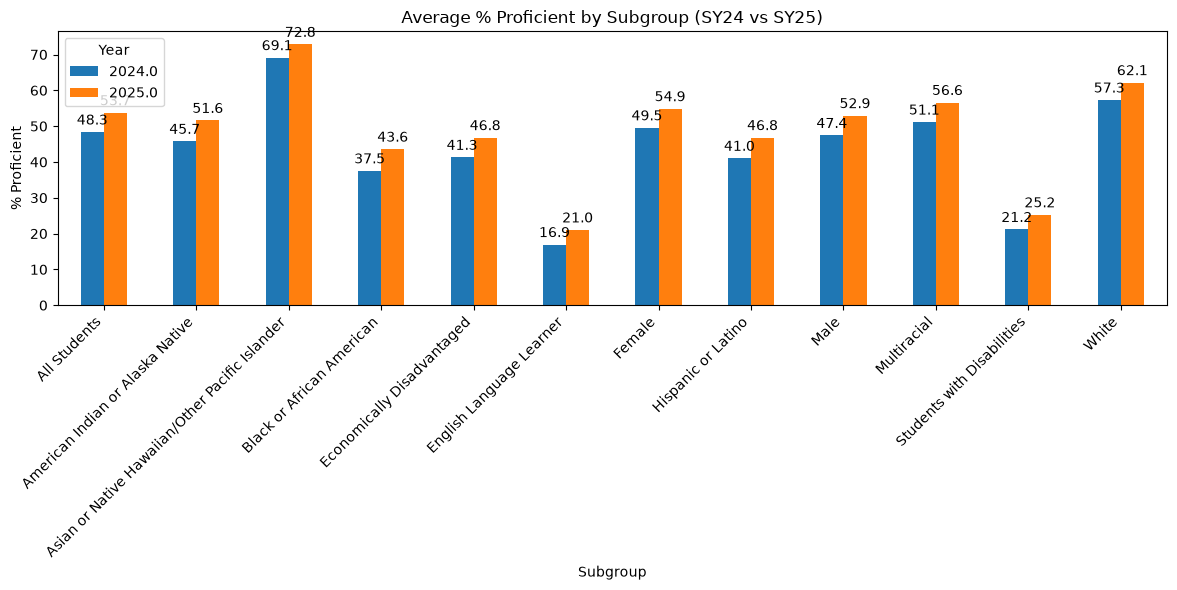

In [17]:
pivot_data = chart_data.pivot(index='SUBGROUP_NAME', columns='YEAR', values='PER_PROF_num')

ax = pivot_data.plot(kind='bar', figsize=(12, 6))
plt.title("Average % Proficient by Subgroup (SY24 vs SY25)")
plt.xlabel("Subgroup")
plt.ylabel("% Proficient")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Year")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)
plt.tight_layout()
plt.show()

In [20]:
subject_trend = df_scores[df_scores["SUBGROUP_NAME"] == "All Students"].groupby(["YEAR", "SUBJECT"])["PER_PROF_num"].mean().reset_index()
subject_trend

,YEAR,SUBJECT,PER_PROF_num
0,2024.0,ELA,45.440955
1,2024.0,Math,51.307898
2,2025.0,ELA,53.105450
3,2025.0,Math,54.382411


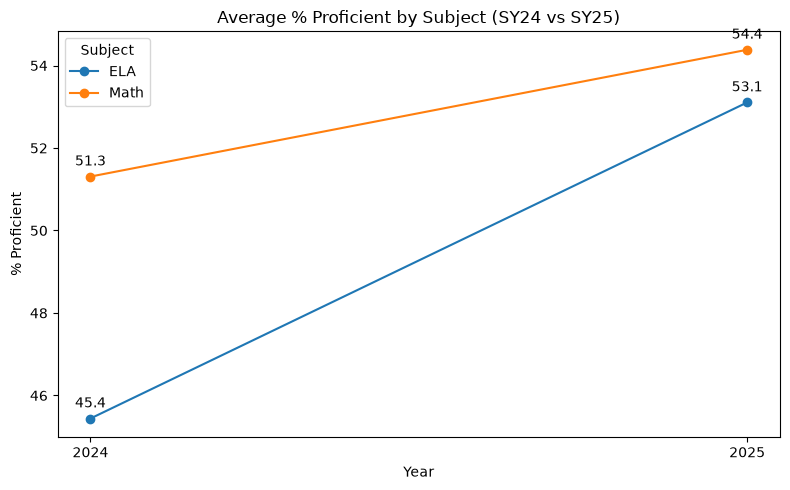

In [24]:
subject_trend["YEAR"] = subject_trend["YEAR"].astype(float).astype(int)
pivot_subject = subject_trend.pivot(index="YEAR", columns="SUBJECT", values="PER_PROF_num")

ax = pivot_subject.plot(kind="line", marker="o", figsize=(8, 5))
plt.title("Average % Proficient by Subject (SY24 vs SY25)")
plt.xlabel("Year")
plt.ylabel("% Proficient")
plt.xticks(pivot_subject.index)
plt.legend(title="Subject")

for subject in pivot_subject.columns:
    for year, value in pivot_subject[subject].items():
        ax.annotate(f"{value:.1f}", (year, value), textcoords="offset points", xytext=(0, 8), ha='center')

plt.tight_layout()
plt.show()